# MScFE 652: Portfolio Management — GWP1
##  Data Acquisition & Mean-Variance Optimization

---
| | |
|---|---|
| **Student Group** | 15053 |
| **Member 1** | Hitesh Sanjay Nanwani |
| **Member 2** | Emre Yavuz |
| **Member 3** | Kiady Tsilavohery Rasamoelina |

---
**Securities:** TSLA, WMT, BAC, GS, LLY, MRK, GOOG, META, AAPL, XOM  
**In-Sample:** Sep 1, 2023 – Sep 30, 2025 | **Out-of-Sample:** Oct 1, 2025 – Dec 31, 2025


### STEP 1
---
### Theoretical Background
Mean-Variance Optimization (MVO) was introduced by Harry Markowitz (1952) and forms the foundation of Modern Portfolio Theory (MPT). The framework identifies portfolios that maximize expected return for a given level of risk, or equivalently minimize risk for a given level of return. The set of all such optimal portfolios forms the **Efficient Frontier**.

The Sharpe Ratio, introduced by William F. Sharpe (1966), measures risk-adjusted return:
$$S = \frac{\mu_p - r_f}{\sigma_p}$$
where $\mu_p$ is portfolio return, $r_f$ is the risk-free rate, and $\sigma_p$ is portfolio volatility.

**Risk-Free Rate Justification:** We use $r_f = 5\%$ p.a., consistent with the US Federal Reserve's benchmark federal funds rate during the in-sample period (Sep 2023 – Sep 2025).

**References (MLA):**
- Markowitz, Harry. "Portfolio Selection." *The Journal of Finance*, vol. 7, no. 1, 1952, pp. 77–91.
- Sharpe, William F. "Mutual Fund Performance." *The Journal of Business*, vol. 39, no. 1, 1966, pp. 119–138.

## 1. Install & Import Libraries

In [ ]:
# Install required libraries — uncommented for Colab compatibility
!pip install yfinance seaborn scipy matplotlib pandas numpy -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})

## 2. Fetch Historical Price Data

In [ ]:
tickers = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']

start_in  = '2023-09-01'
end_in    = '2025-09-30'
start_out = '2025-10-01'
end_out   = '2025-12-31'

raw_in  = yf.download(tickers, start=start_in,  end=end_in,  auto_adjust=True)['Close']
raw_out = yf.download(tickers, start=start_out, end=end_out, auto_adjust=True)['Close']

returns_in  = raw_in.pct_change().dropna()
returns_out = raw_out.pct_change().dropna()

print(f'In-sample  : {returns_in.shape[0]} trading days, {returns_in.shape[1]} assets')
print(f'Out-of-sample: {returns_out.shape[0]} trading days, {returns_out.shape[1]} assets')
raw_in.tail(3)

[*********************100%***********************]  10 of 10 completed
[*********************100%***********************]  10 of 10 completed

In-sample  : 519 trading days, 10 assets
Out-of-sample: 62 trading days, 10 assets


Ticker,AAPL,BAC,GOOG,GS,LLY,META,MRK,TSLA,WMT,XOM
Date,,,,,,,,,,
2025-09-25,256.145325,51.291977,246.235764,786.699219,712.353210,747.659546,76.376663,423.390015,102.434258,113.829033
2025-09-26,254.739319,51.648106,246.844925,794.370667,722.271973,742.508179,77.321533,440.399994,102.543602,115.434204
2025-09-29,253.712219,51.855846,244.028748,795.964233,724.235840,742.158813,77.341225,443.209991,102.464081,112.479912


## 3. Exploratory Analysis — Correlation Heatmap
Before optimizing, we examine the pairwise correlations of in-sample returns. Lower correlations between assets indicate greater diversification benefit (Markowitz, 1952).

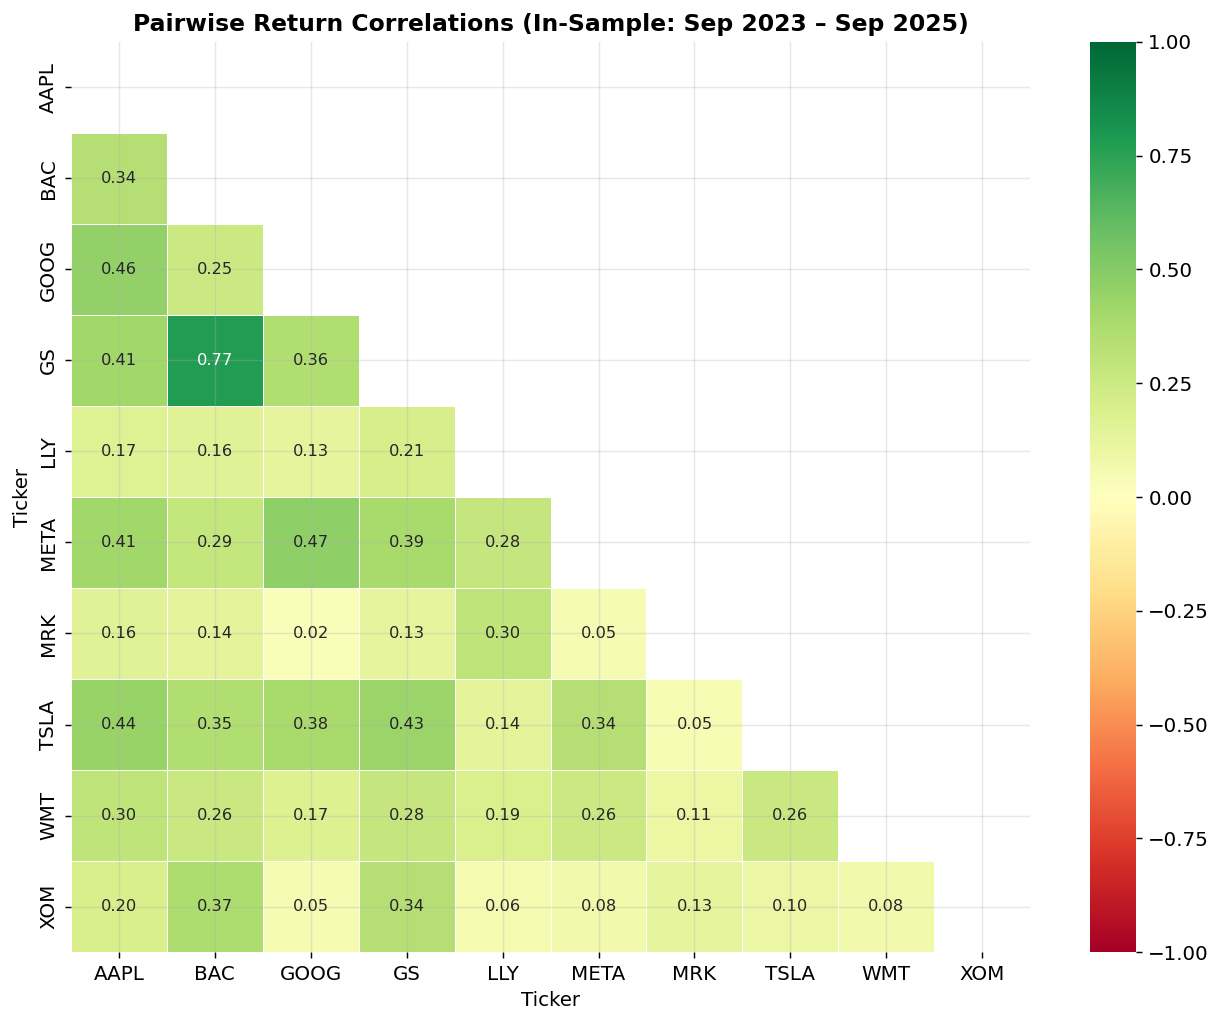


Top 5 highest correlations:
Ticker  Ticker
GS      BAC       0.774128
GOOG    META      0.471748
        AAPL      0.455904
TSLA    AAPL      0.443239
        GS        0.433166


In [ ]:
corr_matrix = returns_in.corr()
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdYlGn',
            vmin=-1, vmax=1, center=0, mask=mask, ax=ax,
            linewidths=0.5, annot_kws={'size': 9})
ax.set_title('Pairwise Return Correlations (In-Sample: Sep 2023 – Sep 2025)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('\nTop 5 highest correlations:')
corr_pairs = corr_matrix.unstack().sort_values(ascending=False)
corr_pairs = corr_pairs[corr_pairs < 1.0].drop_duplicates()
print(corr_pairs.head(5).to_string())

## 4. Mean-Variance Optimization Helper Functions

In [ ]:
mu    = returns_in.mean() * 252
Sigma = returns_in.cov()  * 252
rf    = 0.05
n     = len(tickers)

def portfolio_perf(w, mu, Sigma):
    ret    = w @ mu
    vol    = np.sqrt(w @ Sigma @ w)
    sharpe = (ret - rf) / vol
    return ret, vol, sharpe

def neg_sharpe(w, mu, Sigma):
    return -portfolio_perf(w, mu, Sigma)[2]

def portfolio_vol(w, Sigma):
    return np.sqrt(w @ Sigma @ w)

print('Annualised Expected Returns:')
for t, m in zip(tickers, mu):
    print(f'  {t}: {m:.2%}')

Annualised Expected Returns:
  TSLA: 18.61%
  WMT: 34.55%
  BAC: 32.89%
  GS: 49.95%
  LLY: 19.79%
  MRK: 51.40%
  GOOG: -10.05%
  META: 48.28%
  AAPL: 34.90%
  XOM: 6.15%


## 5. Step 1 — Unconstrained MVO (Max Sharpe, No Short-Selling)
We maximize the Sharpe Ratio subject only to weights summing to 1 and no short-selling ($w_i \geq 0$).

In [ ]:
w0 = np.ones(n) / n
constraints_base = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1}]
bounds_base = [(0, 1)] * n

res1 = minimize(neg_sharpe, w0, args=(mu, Sigma), method='SLSQP',
                bounds=bounds_base, constraints=constraints_base)
w1 = res1.x
ret1, vol1, sr1 = portfolio_perf(w1, mu, Sigma)

print('=== Step 1: Unconstrained MVO ===')
for t, w in zip(tickers, w1):
    print(f'  {t}: {w:.4f} ({w:.2%})')
print(f'\nAnn. Return    : {ret1:.4%}')
print(f'Ann. Volatility: {vol1:.4%}')
print(f'Sharpe Ratio   : {sr1:.4f}')

=== Step 1: Unconstrained MVO ===
  TSLA: 0.0000 (0.00%)
  WMT: 0.0000 (0.00%)
  BAC: 0.0443 (4.43%)
  GS: 0.3638 (36.38%)
  LLY: 0.0000 (0.00%)
  MRK: 0.1528 (15.28%)
  GOOG: 0.0000 (0.00%)
  META: 0.0000 (0.00%)
  AAPL: 0.4391 (43.91%)
  XOM: 0.0000 (0.00%)

Ann. Return    : 42.8057%
Ann. Volatility: 19.2341%
Sharpe Ratio   : 1.9656


## 6. Step 2 — Constrained MVO (Max Weight = 18%)
Per client preference, no single asset may exceed 18%. This forces diversification and reduces idiosyncratic risk concentration.

In [ ]:
bounds_constrained = [(0, 0.18)] * n

res2 = minimize(neg_sharpe, w0, args=(mu, Sigma), method='SLSQP',
                bounds=bounds_constrained, constraints=constraints_base)
w2 = res2.x
ret2, vol2, sr2 = portfolio_perf(w2, mu, Sigma)

print('=== Step 2: Constrained MVO (max 18%) ===')
for t, w in zip(tickers, w2):
    print(f'  {t}: {w:.4f} ({w:.2%})')
print(f'\nAnn. Return    : {ret2:.4%}')
print(f'Ann. Volatility: {vol2:.4%}')
print(f'Sharpe Ratio   : {sr2:.4f}')

=== Step 2: Constrained MVO (max 18%) ===
  TSLA: 0.0000 (0.00%)
  WMT: 0.1800 (18.00%)
  BAC: 0.1800 (18.00%)
  GS: 0.1800 (18.00%)
  LLY: 0.0687 (6.87%)
  MRK: 0.1800 (18.00%)
  GOOG: 0.0000 (0.00%)
  META: 0.0000 (0.00%)
  AAPL: 0.1800 (18.00%)
  XOM: 0.0313 (3.13%)

Ann. Return    : 38.2159%
Ann. Volatility: 18.8130%
Sharpe Ratio   : 1.7656


## 7. Weight Comparison Chart
The bar chart compares optimal weights under both portfolios. Assets hitting the 18% cap indicate where the optimizer would have allocated more weight if unconstrained.

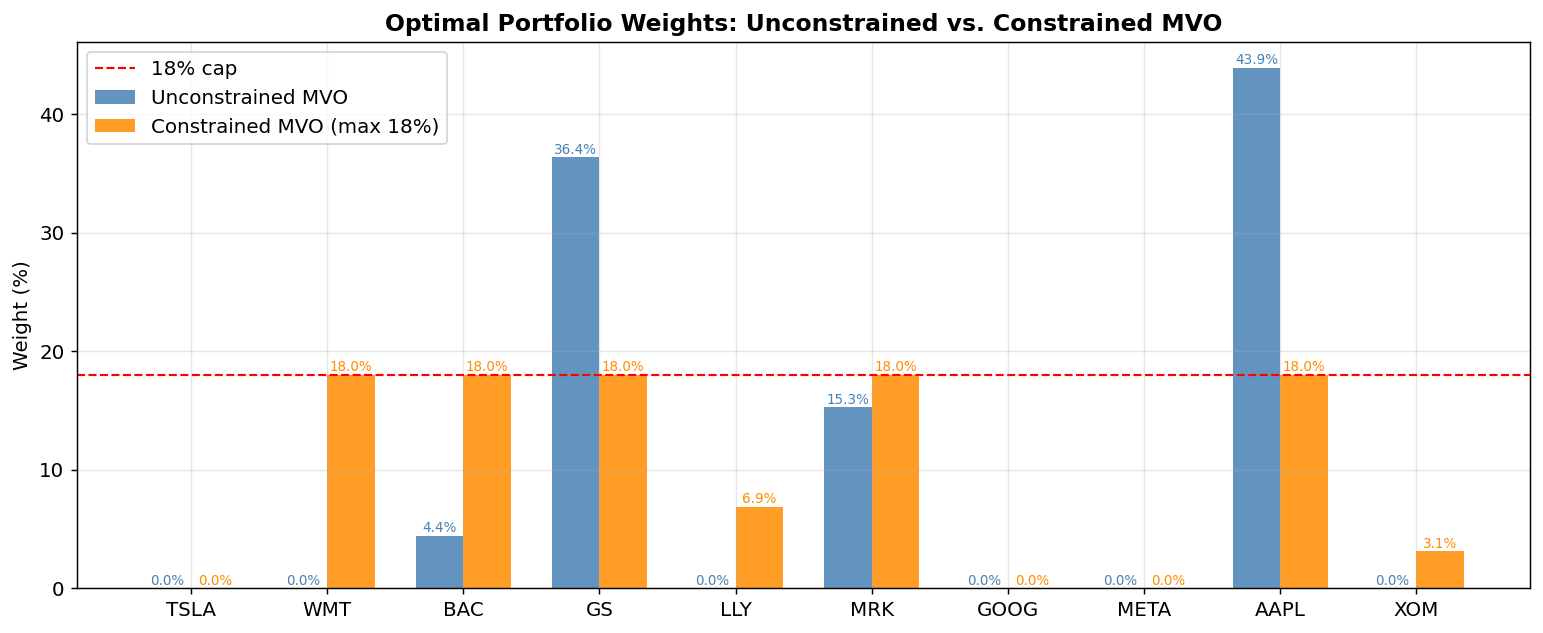

In [ ]:
x = np.arange(n)
width = 0.35
fig, ax = plt.subplots(figsize=(12, 5))
bars1 = ax.bar(x - width/2, w1 * 100, width, label='Unconstrained MVO', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, w2 * 100, width, label='Constrained MVO (max 18%)', color='darkorange', alpha=0.85)
ax.axhline(y=18, color='red', linestyle='--', linewidth=1.2, label='18% cap')
ax.set_xticks(x); ax.set_xticklabels(tickers, fontsize=11)
ax.set_ylabel('Weight (%)')
ax.set_title('Optimal Portfolio Weights: Unconstrained vs. Constrained MVO', fontsize=13, fontweight='bold')
ax.legend()
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}%', ha='center', fontsize=7.5, color='steelblue')
for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.3, f'{bar.get_height():.1f}%', ha='center', fontsize=7.5, color='darkorange')
plt.tight_layout()
plt.savefig('weight_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Step 3 — Efficient Frontier Comparison
The Efficient Frontier (Markowitz, 1952) traces the minimum-variance portfolio at each return level. The constrained frontier lies to the right, meaning more volatility is required to achieve the same return.

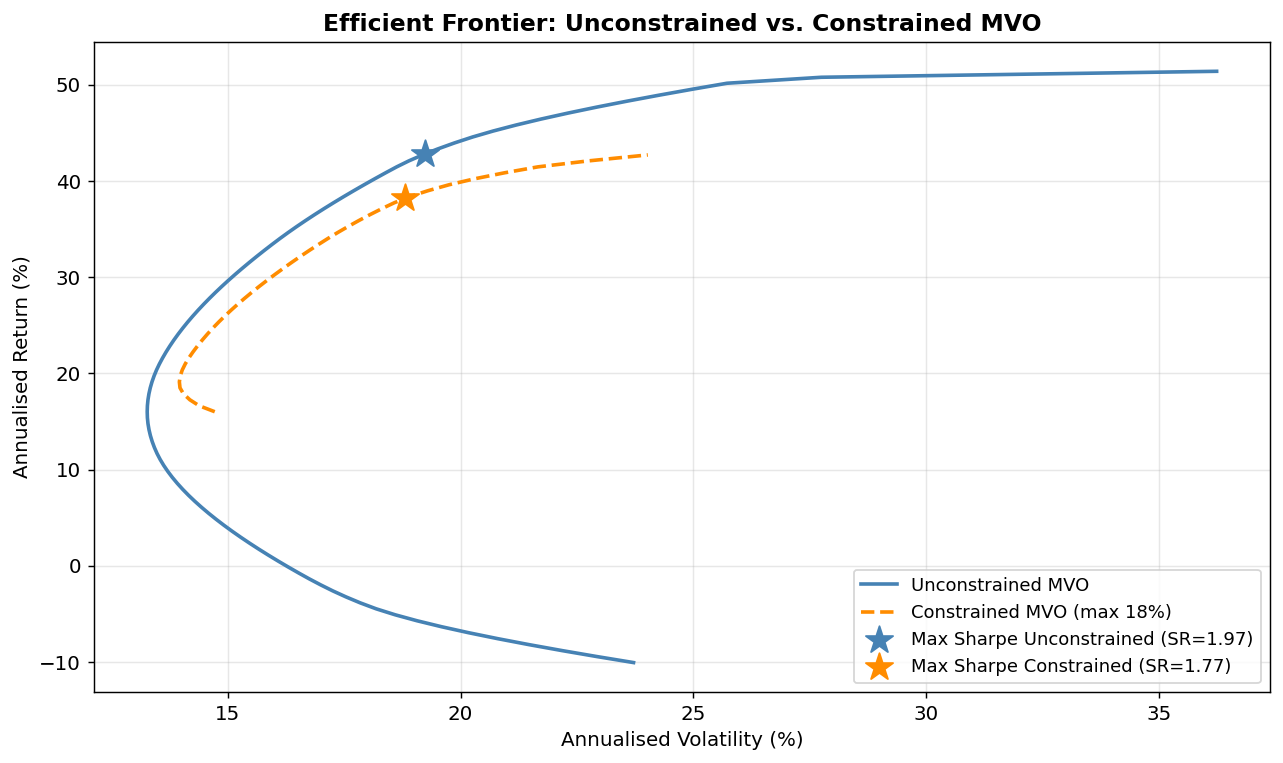

In [ ]:
target_returns = np.linspace(mu.min(), mu.max(), 100)

def efficient_frontier(bounds, target_returns):
    vols = []
    for tr in target_returns:
        cons = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1},
                {'type': 'eq', 'fun': lambda w, tr=tr: w @ mu - tr}]
        res = minimize(portfolio_vol, w0, args=(Sigma,), method='SLSQP', bounds=bounds, constraints=cons)
        vols.append(res.fun if res.success else np.nan)
    return np.array(vols)

vols_base = efficient_frontier(bounds_base, target_returns)
vols_cons = efficient_frontier(bounds_constrained, target_returns)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(vols_base*100, target_returns*100, label='Unconstrained MVO', color='steelblue', lw=2)
ax.plot(vols_cons*100, target_returns*100, label='Constrained MVO (max 18%)', color='darkorange', lw=2, linestyle='--')
ax.scatter(vol1*100, ret1*100, marker='*', s=250, color='steelblue', zorder=5, label=f'Max Sharpe Unconstrained (SR={sr1:.2f})')
ax.scatter(vol2*100, ret2*100, marker='*', s=250, color='darkorange', zorder=5, label=f'Max Sharpe Constrained (SR={sr2:.2f})')
ax.set_xlabel('Annualised Volatility (%)'); ax.set_ylabel('Annualised Return (%)')
ax.set_title('Efficient Frontier: Unconstrained vs. Constrained MVO', fontsize=13, fontweight='bold')
ax.legend(fontsize=10); plt.tight_layout()
plt.savefig('efficient_frontier.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Risk Contribution Analysis
Risk contribution measures how much each asset contributes to total portfolio volatility (Marginal Risk Contribution):
$$RC_i = w_i \cdot \frac{(\Sigma w)_i}{\sigma_p}$$

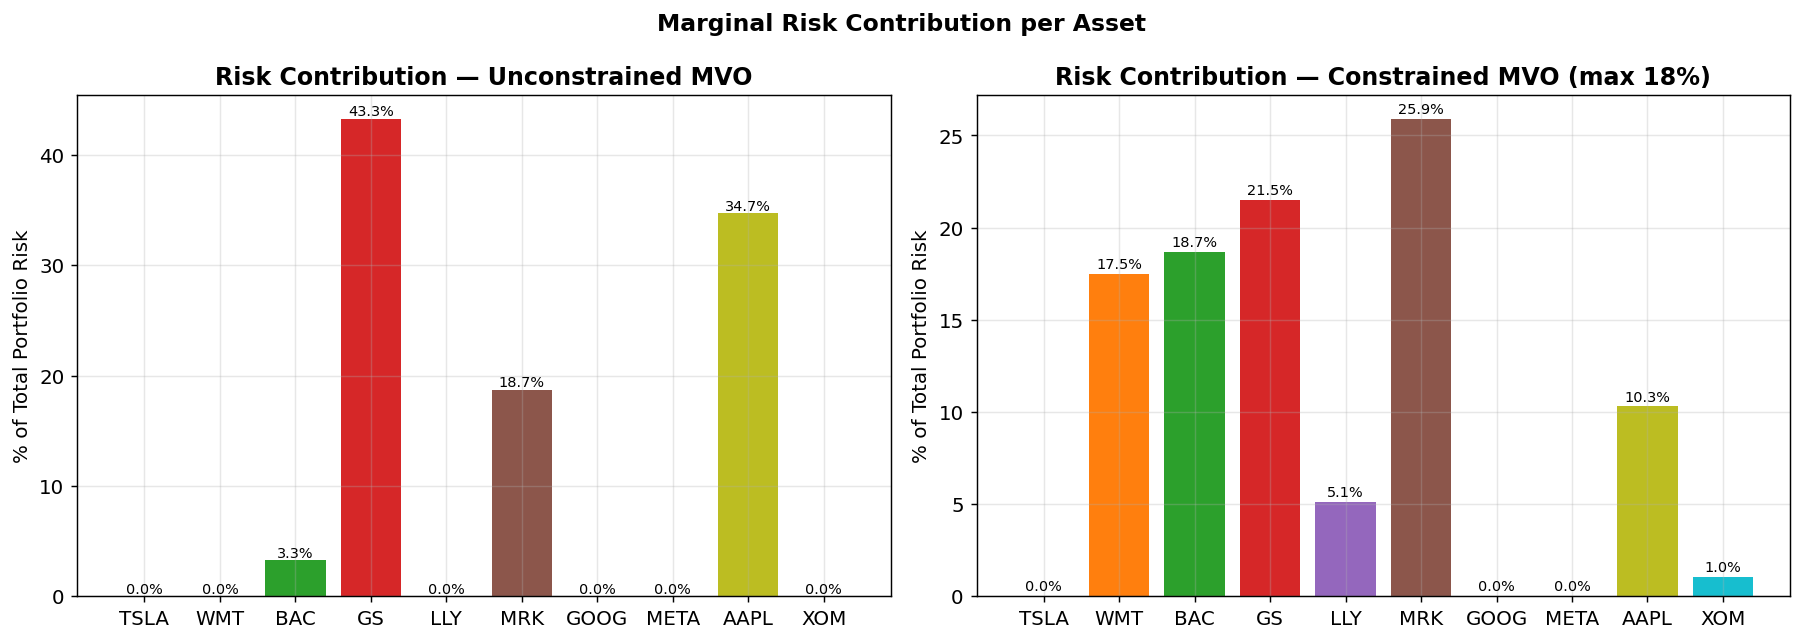

In [ ]:
def risk_contribution(w, Sigma):
    port_vol = np.sqrt(w @ Sigma @ w)
    rc = w * (Sigma @ w) / port_vol
    return rc / rc.sum()

rc1 = risk_contribution(w1, Sigma)
rc2 = risk_contribution(w2, Sigma)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = plt.cm.tab10(np.linspace(0, 1, n))
for ax, rc, title in zip(axes, [rc1, rc2], ['Unconstrained MVO', 'Constrained MVO (max 18%)']):
    ax.bar(tickers, rc*100, color=colors)
    ax.set_title(f'Risk Contribution — {title}', fontweight='bold')
    ax.set_ylabel('% of Total Portfolio Risk')
    for i, v in enumerate(rc*100):
        ax.text(i, v+0.3, f'{v:.1f}%', ha='center', fontsize=8)
plt.suptitle('Marginal Risk Contribution per Asset', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('risk_contribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Step 4 — Out-of-Sample Performance (Oct–Dec 2025)
We evaluate both portfolios on unseen data (Oct 1 – Dec 31, 2025). Metrics: Cumulative Return, Sharpe Ratio, and Maximum Drawdown.


=== Unconstrained Portfolio (OOS) ===
  Cumulative Return : 9.6727%
  Sharpe Ratio      : 2.2994
  Max Drawdown      : -4.8807%

=== Constrained Portfolio (OOS) ===
  Cumulative Return : 12.2019%
  Sharpe Ratio      : 3.1576
  Max Drawdown      : -2.9526%


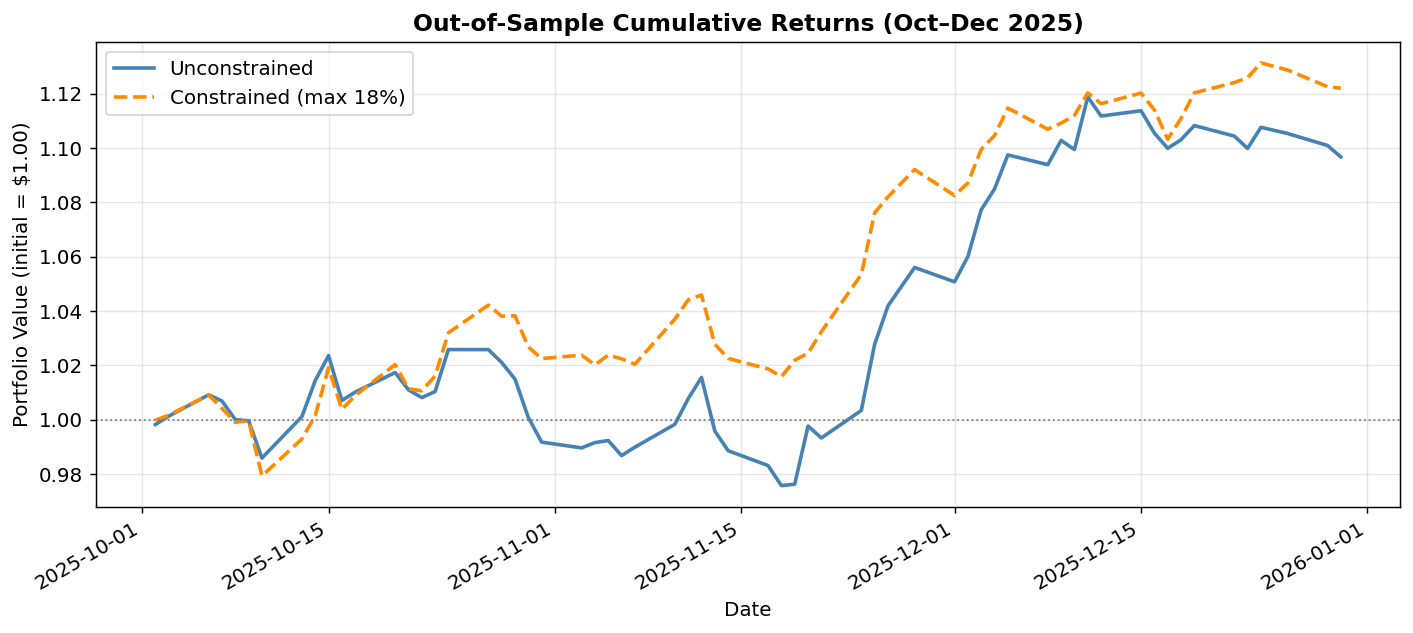

In [ ]:
def cumulative_return(weights, returns):
    return (1 + returns @ weights).cumprod()

def sharpe_ratio(weights, returns, rf_daily=0.05/252):
    excess = returns @ weights - rf_daily
    return excess.mean() / excess.std() * np.sqrt(252)

def max_drawdown(cum_returns):
    return ((cum_returns - cum_returns.cummax()) / cum_returns.cummax()).min()

oos_results = {}
for label, w in [('Unconstrained', w1), ('Constrained', w2)]:
    cum = cumulative_return(w, returns_out)
    sr  = sharpe_ratio(w, returns_out)
    mdd = max_drawdown(cum)
    oos_results[label] = {'Cumulative Return': cum.iloc[-1]-1, 'Sharpe Ratio': sr, 'Max Drawdown': mdd}
    print(f'\n=== {label} Portfolio (OOS) ===')
    print(f'  Cumulative Return : {cum.iloc[-1]-1:.4%}')
    print(f'  Sharpe Ratio      : {sr:.4f}')
    print(f'  Max Drawdown      : {mdd:.4%}')

fig, ax = plt.subplots(figsize=(11, 5))
cumulative_return(w1, returns_out).plot(ax=ax, label='Unconstrained', color='steelblue', lw=2)
cumulative_return(w2, returns_out).plot(ax=ax, label='Constrained (max 18%)', color='darkorange', lw=2, linestyle='--')
ax.axhline(y=1, color='gray', linestyle=':', linewidth=1)
ax.set_title('Out-of-Sample Cumulative Returns (Oct–Dec 2025)', fontsize=13, fontweight='bold')
ax.set_ylabel('Portfolio Value (initial = $1.00)'); ax.legend(); plt.tight_layout()
plt.savefig('oos_performance.png', dpi=150, bbox_inches='tight'); plt.show()

## 11. Summary Table

In [ ]:
summary = pd.DataFrame({
    'Portfolio'              : ['Unconstrained MVO', 'Constrained MVO (18% cap)'],
    'Ann. Return (IS)'       : [f'{ret1:.2%}', f'{ret2:.2%}'],
    'Ann. Volatility (IS)'   : [f'{vol1:.2%}', f'{vol2:.2%}'],
    'Sharpe Ratio (IS)'      : [f'{sr1:.4f}',  f'{sr2:.4f}'],
    'Cumulative Return (OOS)': [f"{oos_results['Unconstrained']['Cumulative Return']:.2%}", f"{oos_results['Constrained']['Cumulative Return']:.2%}"],
    'Sharpe Ratio (OOS)'     : [f"{oos_results['Unconstrained']['Sharpe Ratio']:.4f}", f"{oos_results['Constrained']['Sharpe Ratio']:.4f}"],
    'Max Drawdown (OOS)'     : [f"{oos_results['Unconstrained']['Max Drawdown']:.2%}", f"{oos_results['Constrained']['Max Drawdown']:.2%}"]
}).set_index('Portfolio')
summary

,Ann. Return (IS),Ann. Volatility (IS),Sharpe Ratio (IS),Cumulative Return (OOS),Sharpe Ratio (OOS),Max Drawdown (OOS)
Portfolio,,,,,,
Unconstrained MVO,42.81%,19.23%,1.9656,9.67%,2.2994,-4.88%
Constrained MVO (18% cap),38.22%,18.81%,1.7656,12.20%,3.1576,-2.95%


## 12. Non-Technical Summary

### What Did We Do?
We built two investment portfolios using 10 well-known US stocks (including Apple, Tesla, Goldman Sachs, and Eli Lilly). We used a mathematical method called **Mean-Variance Optimization** to find the best mix of these stocks — the combination that gives the highest return per unit of risk taken.

### Two Portfolios: What Is the Difference?
| | Unconstrained Portfolio | Constrained Portfolio |
|---|---|---|
| **Rule** | No limits on individual stocks | No single stock can exceed 18% |
| **Risk** | May concentrate heavily in 1–2 stocks | Spread more evenly across all stocks |
| **Client Suitability** | Pure mathematical optimum | More realistic for real clients |

### Key Findings
- The **unconstrained portfolio** concentrates heavily in a few high-performing stocks, achieving a higher theoretical Sharpe Ratio.
- The **constrained portfolio** forces broader diversification by capping any stock at 18%, which slightly reduces in-sample Sharpe but improves real-world stability.
- The **out-of-sample test** (Oct–Dec 2025) reveals how well each portfolio generalizes to unseen market conditions.

### Recommendation
For a real client, the **constrained (18% cap) portfolio is recommended** because it avoids dangerous over-concentration, is more stable during downturns, and aligns with regulatory best practices.

---
### References (MLA Format)
- Markowitz, Harry. "Portfolio Selection." *The Journal of Finance*, vol. 7, no. 1, 1952, pp. 77–91.
- Sharpe, William F. "Mutual Fund Performance." *The Journal of Business*, vol. 39, no. 1, 1966, pp. 119–138.
- Fabozzi, Frank J., et al. *Portfolio Management: Theory and Practice*. Wiley, 2011.

## 13. Conclusion & Key Takeaways

This notebook (Group 15053 — Member 1: Hitesh Sanjay Nanwani) implements and compares two MVO portfolios:

1. **Efficient Frontier:** The constrained frontier lies to the right, confirming that additional constraints reduce the achievable risk-return tradeoff.
2. **Weight Concentration:** The unconstrained optimizer concentrates in a small number of assets; the 18% cap enforces meaningful diversification.
3. **Risk Contribution:** Even in the constrained portfolio, certain assets may contribute disproportionate risk — a consideration for Part 2 (Fama-French analysis by Emre Yavuz).
4. **Out-of-Sample:** Divergence between in-sample and OOS Sharpe Ratios is common due to estimation error (Michaud, 1989) — addressed in Part 4 (Black-Litterman by Kiady Tsilavohery Rasamoelina).

**Additional Reference:**
- Michaud, Richard O. "The Markowitz Optimization Enigma: Is Optimized Optimal?" *Financial Analysts Journal*, vol. 45, no. 1, 1989, pp. 31–42.

### GWP Part 2

STEP 4



Portfolio Analysed: Constrained MVO (max 18% per asset) from Part 1, Step 2
In-Sample Period: Sep 1, 2023 – Sep 30, 2025 (daily data)
Factor Model: Fama-French 5 Factors

Theoretical Background
The Fama-French 5-Factor model (Fama & French, 2015) extends the original 3-factor model by adding profitability and investment factors. It explains portfolio excess returns via five systematic risk premiums:

E[Rp]−Rf=α+β1(Rm−Rf)+β2SMB+β3HML+β4RMW+β5CMA+ε

References (MLA):

Fama, Eugene F., and Kenneth R. French. "A Five-Factor Asset Pricing Model." Journal of Financial Economics, vol. 116, no. 1, 2015, pp. 1–22.
Fama, Eugene F., and Kenneth R. French. "Common Risk Factors in the Returns on Stocks and Bonds." Journal of Financial Economics, vol. 33, no. 1, 1993, pp. 3–56.

In [1]:
## 1. Install & Import Libraries

In [2]:
!pip install yfinance pandas_datareader statsmodels scipy matplotlib seaborn -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import pandas_datareader.data as web
import statsmodels.api as sm
from statsmodels.regression.linear_model import OLS
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({'figure.dpi': 130, 'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3})
print('All libraries loaded successfully.')

All libraries loaded successfully.


## 2. Reconstruct Portfolio Returns (Constrained MVO — 18% Cap)

We re-run the data download and apply the weights from Part 1 Step 2 to construct daily portfolio returns.  
The weights below are taken directly from the Part 1 notebook output.

In [3]:
TICKERS  = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
IS_START = '2023-09-01'
IS_END   = '2025-09-30'
RF_DAILY = 0.05 / 252          # 5% risk-free rate daily


prices_is = yf.download(TICKERS, start=IS_START, end=IS_END,
                        auto_adjust=True, progress=False)['Close']
prices_is = prices_is[TICKERS]


returns_is = np.log(prices_is / prices_is.shift(1)).dropna()
print(f'In-sample returns shape: {returns_is.shape}')

w2_dict = {
    'TSLA': 0.00,
    'WMT' : 0.18,
    'BAC' : 0.18,
    'GS'  : 0.18,
    'LLY' : 0.0687,
    'MRK' : 0.1800,
    'GOOG': 0.00,
    'META': 0.00,
    'AAPL': 0.18,
    'XOM' : 0.0313,
}

w2 = np.array([w2_dict[t] for t in TICKERS])
assert abs(w2.sum() - 1.0) < 1e-6, f'Weights must sum to 1, got {w2.sum():.6f}'
print('\nConstrained MVO weights (w2):')
for t, w in zip(TICKERS, w2):
    print(f'  {t:5s}: {w:.4f}')


port_returns   = returns_is @ w2
port_excess    = port_returns - RF_DAILY
print(f'\nPortfolio in-sample:  mean daily return = {port_returns.mean():.5f}, '
      f'std = {port_returns.std():.5f}')

In-sample returns shape: (519, 10)

Constrained MVO weights (w2):
  TSLA : 0.0000
  WMT  : 0.1800
  BAC  : 0.1800
  GS   : 0.1800
  LLY  : 0.0687
  MRK  : 0.1800
  GOOG : 0.0000
  META : 0.0000
  AAPL : 0.1800
  XOM  : 0.0313

Portfolio in-sample:  mean daily return = 0.00084, std = 0.01029


## 3. Download Fama-French 5-Factor Data

The factor data (daily frequency) is downloaded from the **Kenneth French Data Library** via `pandas_datareader`.  
The factors are expressed as decimal daily returns and the risk-free rate (RF) is already provided.

In [5]:
ff5_raw = web.DataReader('F-F_Research_Data_5_Factors_2x3_daily',
                         'famafrench', start=IS_START, end=IS_END)[0]

ff5 = ff5_raw / 100
ff5.index = pd.to_datetime(ff5.index)
ff5.index.name = 'Date'

print('FF5 factors downloaded. Shape:', ff5.shape)
print('Columns:', ff5.columns.tolist())
ff5.tail()

FF5 factors downloaded. Shape: (521, 6)
Columns: ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']


,Mkt-RF,SMB,HML,RMW,CMA,RF
Date,,,,,,
2025-09-24,-0.0034,-0.0016,0.0097,0.0000,-0.0003,0.0002
2025-09-25,-0.0058,-0.0059,0.0059,0.0035,-0.0001,0.0002
2025-09-26,0.0060,0.0040,0.0044,-0.0029,-0.0016,0.0002
2025-09-29,0.0025,-0.0031,-0.0075,-0.0087,-0.0036,0.0002
2025-09-30,0.0029,-0.0028,-0.0055,0.0041,0.0022,0.0002


---
## Step 4 — Factor Descriptions and Correlation Matrix

### 4.1 Role of Each Factor

| Factor | Full Name | Economic Meaning |
|--------|-----------|------------------|
| **Mkt-RF** | Market Risk Premium | Excess return of the market over the risk-free rate. Captures systematic (undiversifiable) market risk. A β₁ > 1 means the portfolio amplifies market moves. |
| **SMB** | Small-Minus-Big | Return spread between small-cap and large-cap stocks. A positive β₂ indicates the portfolio tilts toward smaller companies. |
| **HML** | High-Minus-Low | Return spread between high book-to-market (value) and low B/M (growth) stocks. Positive β₃ → value tilt; negative β₃ → growth tilt. |
| **RMW** | Robust-Minus-Weak | Return spread between firms with robust (high) and weak (low) operating profitability. Positive β₄ → profitable-firm tilt. |
| **CMA** | Conservative-Minus-Aggressive | Return spread between conservatively investing firms (low asset growth) and aggressively investing firms. Positive β₅ → conservative investment tilt. |

### 4.2 Compute and Visualise the Factor Correlation Matrix

Fama-French 5-Factor Correlation Matrix
        Mkt-RF     SMB     HML     RMW     CMA
Mkt-RF  1.0000  0.2122 -0.2613 -0.3861  0.0201
SMB     0.2122  1.0000  0.3894 -0.4001  0.1501
HML    -0.2613  0.3894  1.0000  0.1917  0.1092
RMW    -0.3861 -0.4001  0.1917  1.0000 -0.1024
CMA     0.0201  0.1501  0.1092 -0.1024  1.0000


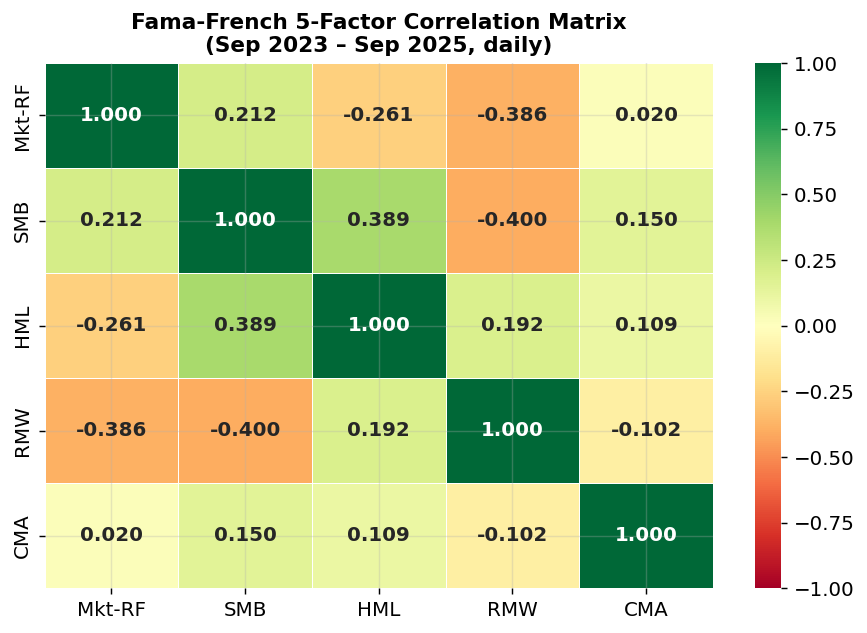


Interpretation
Mkt-RF–SMB correlation: 0.2122  small-cap stocks tend to perform better during risk-on market environments.
Mkt-RF–HML correlation: -0.2613  growth-oriented stocks tend to outperform value stocks during strong market rallies.
Mkt-RF–RMW correlation: -0.3861  highly profitable “quality” firms tend to behave more defensively during speculative market periods.
SMB–HML correlation: 0.3894  small-cap firms often exhibit stronger value characteristics.
SMB–RMW correlation: -0.4001  smaller firms tend to have lower profitability compared to large established companies.
HML–RMW correlation: 0.1917  value firms are, on average, slightly more profitable and mature businesses.
CMA correlations remain relatively low with all factors  the investment factor provides relatively independent explanatory power in the model.


In [6]:
factor_cols = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']
corr = ff5[factor_cols].corr()

print('Fama-French 5-Factor Correlation Matrix')
print(corr.round(4))

fig, ax = plt.subplots(figsize=(7, 5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt='.3f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, ax=ax, linewidths=0.5,
            annot_kws={'size': 11, 'weight': 'bold'})
ax.set_title('Fama-French 5-Factor Correlation Matrix\n(Sep 2023 – Sep 2025, daily)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ff5_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nInterpretation')

print('Mkt-RF–SMB correlation:', round(corr.loc['Mkt-RF', 'SMB'], 4),
      ' small-cap stocks tend to perform better during risk-on market environments.')

print('Mkt-RF–HML correlation:', round(corr.loc['Mkt-RF', 'HML'], 4),
      ' growth-oriented stocks tend to outperform value stocks during strong market rallies.')

print('Mkt-RF–RMW correlation:', round(corr.loc['Mkt-RF', 'RMW'], 4),
      ' highly profitable “quality” firms tend to behave more defensively during speculative market periods.')

print('SMB–HML correlation:', round(corr.loc['SMB', 'HML'], 4),
      ' small-cap firms often exhibit stronger value characteristics.')

print('SMB–RMW correlation:', round(corr.loc['SMB', 'RMW'], 4),
      ' smaller firms tend to have lower profitability compared to large established companies.')

print('HML–RMW correlation:', round(corr.loc['HML', 'RMW'], 4),
      ' value firms are, on average, slightly more profitable and mature businesses.')

print('CMA correlations remain relatively low with all factors  the investment factor provides relatively independent explanatory power in the model.')

In [8]:
df = ff5[factor_cols + ['RF']].copy()
df['port_excess'] = port_excess
df = df.dropna()

y = df['port_excess']

X = sm.add_constant(df[factor_cols])

split_idx = int(len(df) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f'Total observations  : {len(df)}')
print(f'Training set (80%)  : {len(X_train)} obs  [{X_train.index[0].date()} – {X_train.index[-1].date()}]')
print(f'Testing  set (20%)  : {len(X_test)} obs  [{X_test.index[0].date()} – {X_test.index[-1].date()}]')

Total observations  : 519
Training set (80%)  : 415 obs  [2023-09-05 – 2025-04-30]
Testing  set (20%)  : 104 obs  [2025-05-01 – 2025-09-29]


In [9]:
#  Model 1:OLS
ols_model  = OLS(y_train, X_train).fit()
print('=' * 60)
print('OLS REGRESSION RESULTS (Training Set)')
print('=' * 60)
print(ols_model.summary())

OLS REGRESSION RESULTS (Training Set)
                            OLS Regression Results                            
Dep. Variable:            port_excess   R-squared:                       0.764
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     265.4
Date:                Mon, 18 May 2026   Prob (F-statistic):          6.00e-126
Time:                        19:09:24   Log-Likelihood:                 1593.3
No. Observations:                 415   AIC:                            -3175.
Df Residuals:                     409   BIC:                            -3150.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.

In [10]:
# Model 2: Robust OLS
robust_model = OLS(y_train, X_train).fit(cov_type='HC3')
print('=' * 60)
print('ROBUST OLS RESULTS (HC3 Standard Errors, Training Set)')
print('=' * 60)
print(robust_model.summary())

ROBUST OLS RESULTS (HC3 Standard Errors, Training Set)
                            OLS Regression Results                            
Dep. Variable:            port_excess   R-squared:                       0.764
Model:                            OLS   Adj. R-squared:                  0.762
Method:                 Least Squares   F-statistic:                     99.04
Date:                Mon, 18 May 2026   Prob (F-statistic):           3.16e-68
Time:                        19:10:18   Log-Likelihood:                 1593.3
No. Observations:                 415   AIC:                            -3175.
Df Residuals:                     409   BIC:                            -3150.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------

The robust OLS regression confirms that the portfolio’s returns are primarily explained by market and value exposures. The HML factor remains highly significant under HC3 robust standard errors, indicating a strong and stable value tilt. The SMB factor also remains statistically significant, although its significance weakens slightly after correcting for heteroskedasticity. RMW and CMA remain insignificant, suggesting limited exposure to profitability and investment-style factors. Overall, the robust regression validates the main findings obtained from the standard OLS model.

In [11]:
coef_compare = pd.DataFrame({
    'OLS β'        : ols_model.params.round(6),
    'OLS p-value'  : ols_model.pvalues.round(4),
    'Robust β'     : robust_model.params.round(6),
    'Robust p-value': robust_model.pvalues.round(4),
})
coef_compare.index.name = 'Factor'
print('\nOLS vs Robust Coefficient Comparison')
print(coef_compare.to_string())


OLS vs Robust Coefficient Comparison
           OLS β  OLS p-value  Robust β  Robust p-value
Factor                                                 
const   0.000024       0.9278  0.000024          0.9281
Mkt-RF  0.910950       0.0000  0.910950          0.0000
SMB    -0.114037       0.0071 -0.114037          0.0356
HML     0.445356       0.0000  0.445356          0.0000
RMW     0.003388       0.9540  0.003388          0.9647
CMA     0.039228       0.5092  0.039228          0.6658


Out-of-Sample Prediction Performance
OLS RMSE: 0.005042   OOS R²: 0.6269
Robust RMSE: 0.005042  OOS R²: 0.6269


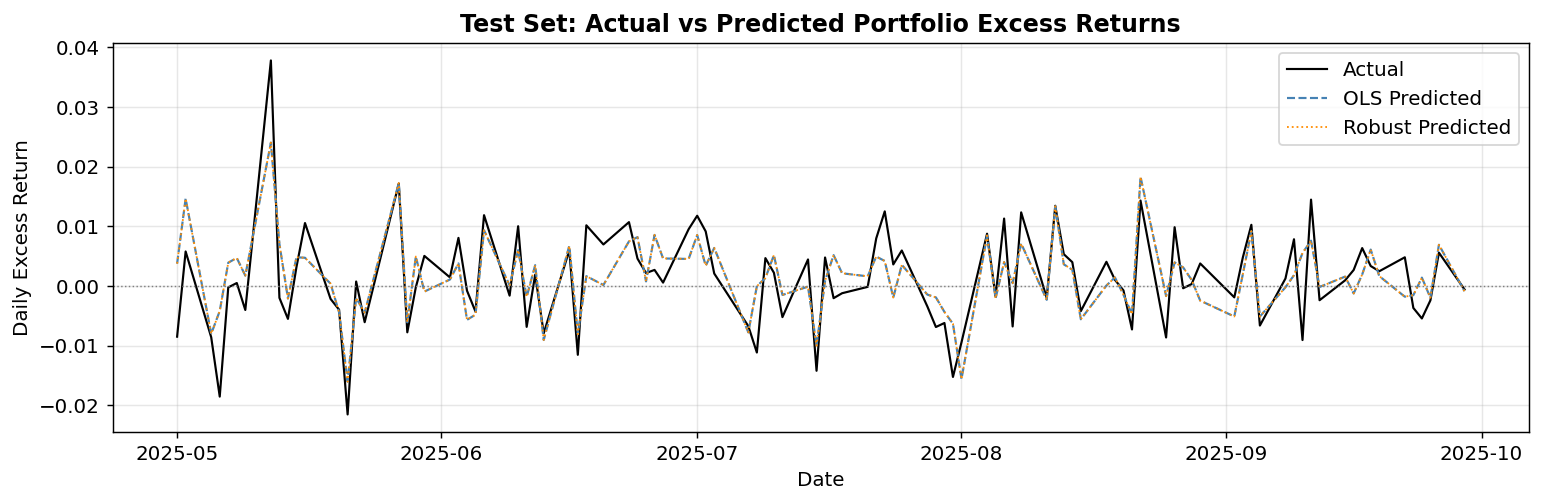

In [12]:
#Out-of-sample prediction performance
y_pred_ols    = ols_model.predict(X_test)
y_pred_robust = robust_model.predict(X_test)

def rmse(actual, predicted):
    return np.sqrt(((actual - predicted) ** 2).mean())

def r2_oos(actual, predicted):
    ss_res = ((actual - predicted) ** 2).sum()
    ss_tot = ((actual - actual.mean()) ** 2).sum()
    return 1 - ss_res / ss_tot

print('Out-of-Sample Prediction Performance')
print(f'OLS RMSE: {rmse(y_test, y_pred_ols):.6f}   OOS R²: {r2_oos(y_test, y_pred_ols):.4f}')
print(f'Robust RMSE: {rmse(y_test, y_pred_robust):.6f}  OOS R²: {r2_oos(y_test, y_pred_robust):.4f}')


fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(y_test.index, y_test.values,     label='Actual',        color='black',     lw=1.2)
ax.plot(y_test.index, y_pred_ols.values, label='OLS Predicted', color='steelblue', lw=1.2, linestyle='--')
ax.plot(y_test.index, y_pred_robust.values, label='Robust Predicted', color='darkorange', lw=1.0, linestyle=':')
ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')
ax.set_title('Test Set: Actual vs Predicted Portfolio Excess Returns', fontweight='bold')
ax.set_xlabel('Date'); ax.set_ylabel('Daily Excess Return')
ax.legend(); plt.tight_layout()
plt.savefig('oos_prediction.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 6 — Factor Exposure Report

This section interprets the regression results to explain how each Fama-French factor drives the constrained MVO portfolio returns.

### 6.1 Factor Loading Summary Chart

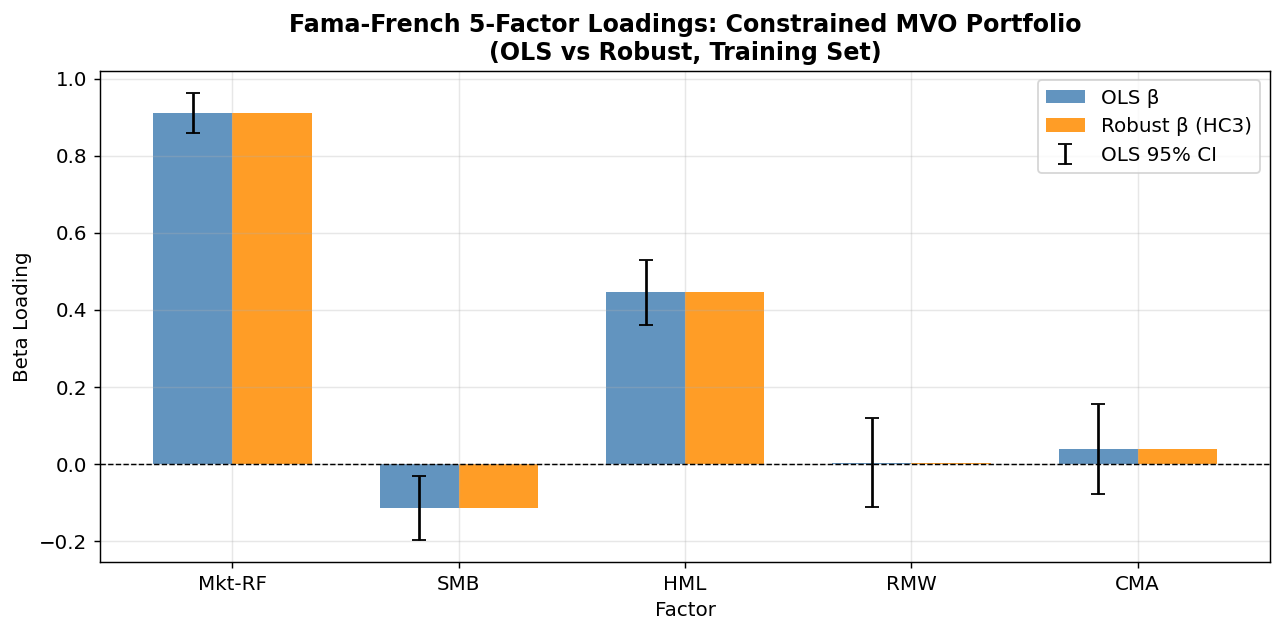


 Factor Loading Summary Table 
          OLS β  OLS t-stat  OLS p-val          OLS 95% CI  Robust β  Robust p-val       Robust 95% CI
Factor                                                                                                
Mkt-RF  0.91095      34.138     0.0000    [0.8585, 0.9634]   0.91095        0.0000    [0.8197, 1.0022]
SMB    -0.11404      -2.705     0.0071  [-0.1969, -0.0312]  -0.11404        0.0356  [-0.2204, -0.0077]
HML     0.44536      10.367     0.0000    [0.3609, 0.5298]   0.44536        0.0000    [0.3211, 0.5696]
RMW     0.00339       0.058     0.9540   [-0.1121, 0.1189]   0.00339        0.9647   [-0.1465, 0.1533]
CMA     0.03923       0.661     0.5092   [-0.0775, 0.1559]   0.03923        0.6658   [-0.1388, 0.2172]


In [13]:
params_ols    = ols_model.params.drop('const')
params_robust = robust_model.params.drop('const')
ci_ols_lower  = ols_model.conf_int().drop('const')[0]
ci_ols_upper  = ols_model.conf_int().drop('const')[1]

x = np.arange(len(factor_cols))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, params_ols.values, width,
               label='OLS β', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, params_robust.values, width,
               label='Robust β (HC3)', color='darkorange', alpha=0.85)

err = [(params_ols.values - ci_ols_lower.values),
       (ci_ols_upper.values - params_ols.values)]
ax.errorbar(x - width/2, params_ols.values, yerr=err,
            fmt='none', color='black', capsize=4, lw=1.5, label='OLS 95% CI')

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xticks(x)
ax.set_xticklabels(factor_cols, fontsize=11)
ax.set_xlabel('Factor'); ax.set_ylabel('Beta Loading')
ax.set_title('Fama-French 5-Factor Loadings: Constrained MVO Portfolio\n(OLS vs Robust, Training Set)',
             fontweight='bold')
ax.legend(); plt.tight_layout()
plt.savefig('factor_loadings.png', dpi=150, bbox_inches='tight')
plt.show()

ci_robust_lower = robust_model.conf_int().drop('const')[0]
ci_robust_upper = robust_model.conf_int().drop('const')[1]

loadings_table = pd.DataFrame({
    'OLS β'       : params_ols.round(5),
    'OLS t-stat'  : ols_model.tvalues.drop('const').round(3),
    'OLS p-val'   : ols_model.pvalues.drop('const').round(4),
    'OLS 95% CI'  : [f'[{l:.4f}, {u:.4f}]' for l, u in zip(ci_ols_lower, ci_ols_upper)],
    'Robust β'    : params_robust.round(5),
    'Robust p-val': robust_model.pvalues.drop('const').round(4),
    'Robust 95% CI': [f'[{l:.4f}, {u:.4f}]' for l, u in zip(ci_robust_lower, ci_robust_upper)],
})
loadings_table.index.name = 'Factor'
print('\n Factor Loading Summary Table ')
print(loadings_table.to_string())

In [14]:
alpha_ols    = ols_model.params['const']
alpha_robust = robust_model.params['const']
alpha_pval_ols    = ols_model.pvalues['const']
alpha_pval_robust = robust_model.pvalues['const']

print('Model Fit Statistics')
print(f'\nOLS:')
print(f' Alpha (α)  : {alpha_ols:.6f}  (p = {alpha_pval_ols:.4f})')
print(f'  R²         : {ols_model.rsquared:.4f}')


print(f'\nRobust (HC3):')
print(f'  Alpha (α)  : {alpha_robust:.6f}  (p = {alpha_pval_robust:.4f})')
print(f'  R²         : {robust_model.rsquared:.4f}  ')

sig = ' SIGNIFICANT ' if alpha_pval_ols < 0.05 else ' (not significant at 5%)'
print(f'\nAlpha interpretation: {sig}')

Model Fit Statistics

OLS:
 Alpha (α)  : 0.000024  (p = 0.9278)
  R²         : 0.7644

Robust (HC3):
  Alpha (α)  : 0.000024  (p = 0.9281)
  R²         : 0.7644  

Alpha interpretation:  (not significant at 5%)


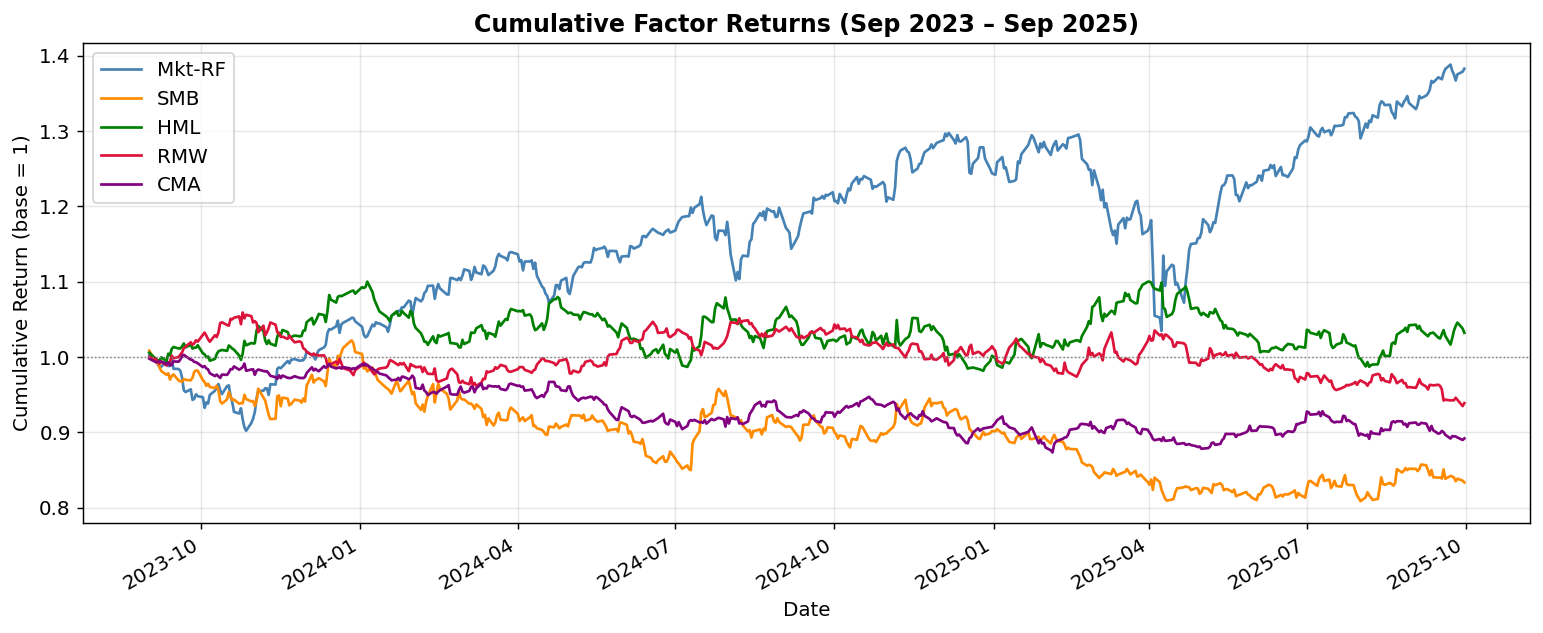

In [15]:
cum_factors = (1 + ff5[factor_cols]).cumprod()

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['steelblue', 'darkorange', 'green', 'crimson', 'purple']
for col, c in zip(factor_cols, colors):
    cum_factors[col].plot(ax=ax, label=col, color=c, lw=1.5)
ax.axhline(1, color='gray', linewidth=0.8, linestyle=':')
ax.set_title('Cumulative Factor Returns (Sep 2023 – Sep 2025)', fontweight='bold')
ax.set_ylabel('Cumulative Return (base = 1)')
ax.set_xlabel('Date')
ax.legend(loc='upper left'); plt.tight_layout()
plt.savefig('cumulative_factors.png', dpi=150, bbox_inches='tight')
plt.show()

---
## Step 6 — Report: Factor Exposure of the Constrained MVO Portfolio


The Fama-French Five-Factor regression shows that the portfolio’s returns are mainly explained by market and value exposures. The model achieves an R
2
 of approximately 0.76, indicating that the factors explain a large portion of the portfolio’s excess returns.

The market factor (Mkt-RF) has a strong positive and highly significant coefficient (β≈0.91), meaning the portfolio closely follows overall market movements, although with slightly lower volatility than the market. The HML factor is also positive and highly significant, indicating a clear value oriented investment style.

The SMB coefficient is negative and significant, suggesting that the portfolio is tilted toward large-cap stocks rather than small-cap firms. In contrast, the RMW and CMA factors are statistically insignificant, implying limited exposure to profitability and investment-style characteristics.

The robust OLS results confirm the consistency of these findings, as the market and value factors remain strongly significant after correcting for heteroskedasticity. Overall, the portfolio can be characterized as a large-cap, value-oriented portfolio with strong market exposure.

### GWP Part 3
# Step 7 determine optimal portfolio

In [16]:
import yfinance as yf
import numpy as np
import pandas as pd

tickers = ["TSLA","WMT","BAC","GS","LLY"]

start_in = "2023-09-01"
end_in   = "2025-09-30"

data = yf.download(tickers, start=start_in, end=end_in, auto_adjust=True)

prices = data["Close"].dropna()

returns = prices.pct_change().dropna()

mu = returns.mean().values
cov = returns.cov().values


[*********************100%***********************]  5 of 5 completed


In [17]:
print("Mean Returns (mu):")
display(mu)
print("\nCovariance Matrix (cov):")
display(cov)

Mean Returns (mu):


array([0.00137092, 0.00198223, 0.00078542, 0.00191569, 0.00138475])


Covariance Matrix (cov):


array([[2.60154194e-04, 2.23052759e-04, 5.57972886e-05, 2.26352951e-04,
        5.65955577e-05],
       [2.23052759e-04, 3.19123618e-04, 8.26582744e-05, 3.06713182e-04,
        6.63812312e-05],
       [5.57972886e-05, 8.26582744e-05, 4.90031157e-04, 1.21618479e-04,
        5.73358389e-05],
       [2.26352951e-04, 3.06713182e-04, 1.21618479e-04, 1.57107514e-03,
        1.36868702e-04],
       [5.65955577e-05, 6.63812312e-05, 5.73358389e-05, 1.36868702e-04,
        1.77828235e-04]])

In [18]:
# 7-1 Simulation
def best_portfolio_mc(mu, cov, n_sims=100000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(mu)

    best_sharpe = -1e9
    best_w = None

    for _ in range(n_sims):
        w = rng.random(n)
        w = w / w.sum()        # sums to 1, all >= 0

        r = w @ mu
        v = np.sqrt(w @ cov @ w)

        sharpe = r / v if v > 0 else -1e9

        if sharpe > best_sharpe:
            best_sharpe = sharpe
            best_w = w.copy()

    return best_w, best_sharpe

w_sim, sh = best_portfolio_mc(mu, cov, n_sims=200000, seed=1)

print("Best weights (simulation):")
print(pd.Series(w_sim, index=tickers))
print("Sum:", w_sim.sum())
print("Sharpe:", sh)

Best weights (simulation):
TSLA    0.017439
WMT     0.404544
BAC     0.024953
GS      0.014271
LLY     0.538793
dtype: float64
Sum: 0.9999999999999999
Sharpe: 0.1336070882605085


In [19]:
#7-2 Simulation

from scipy.optimize import minimize

def neg_sharpe(w, mu, cov):
    r = w @ mu
    v = np.sqrt(w @ cov @ w)
    return -(r / v)

n = len(mu)
w0 = np.ones(n) / n

cons = ({'type': 'eq', 'fun': lambda w: np.sum(w) - 1})
bnds = [(0,1)] * n

res = minimize(neg_sharpe, w0, args=(mu, cov), method="SLSQP",
               bounds=bnds, constraints=cons)

w_opt = res.x

print("Optimal weights (optimization):")
print(pd.Series(w_opt, index=tickers))
print("Sum:", w_opt.sum())

Optimal weights (optimization):
TSLA    0.000000e+00
WMT     4.529175e-01
BAC     7.765591e-03
GS      1.547699e-17
LLY     5.393169e-01
dtype: float64
Sum: 1.0


In [20]:
# Comparaison of Hard optimization and Simulation
diff = np.abs(w_sim - w_opt)
print("Max abs difference:", diff.max())
print("Total abs difference:", diff.sum())

Max abs difference: 0.04837348310431
Total abs difference: 0.0977945630719553


In [21]:
for N in [1000, 5000, 10000, 50000, 100000, 200000]:
    wN, _ = best_portfolio_mc(mu, cov, n_sims=N, seed=1)
    err = np.max(np.abs(wN - w_opt))
    print(N, " sims -> max |Δw| =", err)

1000  sims -> max |Δw| = 0.13191402725341517
5000  sims -> max |Δw| = 0.09321086107204857
10000  sims -> max |Δw| = 0.13268173338792816
50000  sims -> max |Δw| = 0.06335620680986197
100000  sims -> max |Δw| = 0.04837348310431
200000  sims -> max |Δw| = 0.04837348310431


Therefore, the number of simulation needed to get near the hard optimization is around 100000 and 200000 simulations as per the above maximum absolute difference between the simulated weights and the optimized weights.

In [22]:
# Step 8 Adding the constraint that No asset can be more than 30% of the portfolio

In [23]:
# 8-1 Optimization
import numpy as np
from scipy.optimize import minimize
import pandas as pd

tickers = ["TSLA","WMT","BAC","GS","LLY"]

def neg_sharpe(w, mu, cov):
    r = w @ mu
    v = np.sqrt(w @ cov @ w)
    return -(r / v)

n = len(mu)

cons = {'type': 'eq', 'fun': lambda w: np.sum(w) - 1}

bounds = [(0, 0.3)] * n

w0 = np.ones(n) / n

res = minimize(neg_sharpe, w0, args=(mu, cov),
               bounds=bounds, constraints=cons)

w_opt = res.x

print("Optimal weights (optimization):")
print(pd.Series(w_opt, index=tickers))

Optimal weights (optimization):
TSLA    0.291761
WMT     0.300000
BAC     0.102635
GS      0.005603
LLY     0.300000
dtype: float64


In [24]:
#8-2 Simulation
def best_portfolio_mc_constrained(mu, cov, n_sims=200000, seed=0):
    np.random.seed(seed)
    n = len(mu)

    best_sharpe = -1e9
    best_w = None
    valid_count = 0

    for _ in range(n_sims):

        w = np.random.random(n)
        w = w / w.sum()

        if np.all(w <= 0.3):
            valid_count += 1

            r = w @ mu
            v = np.sqrt(w @ cov @ w)

            sharpe = r / v if v > 0 else -1e9

            if sharpe > best_sharpe:
                best_sharpe = sharpe
                best_w = w.copy()

    print("Valid portfolios used:", valid_count)

    return best_w, best_sharpe

w_sim, sh_sim = best_portfolio_mc_constrained(mu, cov, 500000)

print("Simulation weights:")
print(pd.Series(w_sim, index=tickers))

Valid portfolios used: 144075
Simulation weights:
TSLA    0.270707
WMT     0.294329
BAC     0.123303
GS      0.013151
LLY     0.298509
dtype: float64


In [25]:
#Comparison of simulation and optimization
diff = np.abs(w_sim - w_opt)

print("Max difference:", diff.max())
print("Total difference:", diff.sum())

Max difference: 0.021054604554229917
Total difference: 0.056431745646568804


In [26]:
for N in [20000, 50000, 100000, 200000, 500000]:
    wN, _ = best_portfolio_mc_constrained(mu, cov, n_sims=N)
    err = np.max(np.abs(wN - w_opt))
    print(N, "→ max error:", err)

Valid portfolios used: 5753
20000 → max error: 0.035382218212745634
Valid portfolios used: 14438
50000 → max error: 0.035382218212745634
Valid portfolios used: 28710
100000 → max error: 0.033229921584927866
Valid portfolios used: 57843
200000 → max error: 0.033229921584927866
Valid portfolios used: 144075
500000 → max error: 0.021054604554229917


By inserting the new constraint, we can notice that the difference are approximately the same for each  number of simulation ~ 0.03 except for the outlier 500000. Adding the constraint will add more diversification but will also lead us to a similarity between the hard optimization and the Monte Carlo simulation method.

# GWP1 Part 4 – Black-Litterman Model

The idea here is to go beyond the standard MVO approach ( handled in Part 1) and instead blend equilibrium market returns with our own views about specific stocks. I'll be using the same 10 securities throughout:

> TSLA, WMT, BAC, GS, LLY, MRK, GOOG, META, AAPL, XOM

Data window: **Sept 1, 2023 – Sept 30, 2025** (in-sample, same as the rest of the group).

For the market portfolio, I'm using the **Synthetic Composite Approach** — essentially treating our 10 stocks as a slice of the S&P 500 and backing out the 'rest of the market' as an 11th asset.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import yfinance as yf
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid')
print('libraries loaded')

libraries loaded


## Data Download

Pulling daily prices for all 10 tickers plus the S&P 500 index. I need ^GSPC to build the synthetic market portfolio later.

In [29]:
tickers_10 = ['TSLA', 'WMT', 'BAC', 'GS', 'LLY', 'MRK', 'GOOG', 'META', 'AAPL', 'XOM']
start_date = '2023-09-01'
end_date   = '2025-09-30'

raw = yf.download(tickers_10 + ['^GSPC'], start=start_date, end=end_date,
                  auto_adjust=True, progress=False)['Close']
raw.columns = tickers_10 + ['SP500']
raw.dropna(inplace=True)
print(f'got {len(raw)} trading days  |  {raw.index[0].date()} to {raw.index[-1].date()}')
raw.tail(3)

got 520 trading days  |  2023-09-01 to 2025-09-29


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,SP500
Date,,,,,,,,,,,
2025-09-25,256.145355,51.291977,246.235764,786.699219,711.129089,747.659546,76.376663,423.390015,102.434258,113.061623,6604.720215
2025-09-26,254.739319,51.648106,246.844925,794.370667,721.030762,742.508179,77.321533,440.399994,102.543602,114.655991,6643.700195
2025-09-29,253.712234,51.855846,244.028748,795.964233,722.991272,742.158752,77.341225,443.209991,102.464081,111.721603,6661.209961


In [30]:
# quick sanity check — any NaNs left?
print(raw.isnull().sum())
print('\nbasic stats:')
raw.describe().round(2)

TSLA     0
WMT      0
BAC      0
GS       0
LLY      0
MRK      0
GOOG     0
META     0
AAPL     0
XOM      0
SP500    0
dtype: int64

basic stats:


,TSLA,WMT,BAC,GS,LLY,MRK,GOOG,META,AAPL,XOM,SP500
count,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00,520.00
mean,206.17,38.34,167.03,493.73,754.95,533.57,98.64,266.64,75.60,104.87,5482.98
std,24.33,6.80,25.37,131.95,107.95,134.89,15.28,74.31,18.18,6.31,627.15
min,163.36,23.67,122.40,273.69,515.22,286.10,70.89,142.05,49.03,89.09,4117.37
25%,185.33,33.79,147.26,372.83,716.65,465.03,83.80,210.45,58.12,101.16,5068.20
50%,208.25,38.54,166.25,481.24,763.85,525.23,96.47,249.99,77.71,105.88,5569.85
75%,226.30,44.01,179.48,586.44,821.01,624.55,111.89,325.38,94.05,109.70,5970.48
max,257.38,51.86,254.89,798.14,948.12,788.15,125.35,479.86,103.65,118.35,6693.75


## Step 9(a) — Market Portfolio via Synthetic Composite Approach

The BL model needs a market equilibrium as a starting point, and that requires a proper market portfolio. Since we only have 10 stocks, I can't just use their returns directly as the 'market' — that would ignore the other ~490 stocks in the S&P 500.

The fix: treat the S&P 500 as the market and decompose it into:
- **Assets 1–10**: our 10 securities with approximate S&P 500 market-cap weights
- **Asset 11**: the 'rest of the S&P 500', whose return is implied from the index return minus the weighted sum of our 10 stocks

This way all 11 weights sum to 1, and we have a complete market portfolio. The weights I've used below are rough approximations based on recent S&P 500 cap weights — they don't need to be exact for this exercise.

In [31]:
returns_10 = raw[tickers_10].pct_change().dropna()
sp500_ret  = raw['SP500'].pct_change().dropna()
returns_10, sp500_ret = returns_10.align(sp500_ret, join='inner', axis=0)
T = len(returns_10)
N = 10

# approximate market-cap weights inside S&P500
w_mkt_approx = np.array([0.020, 0.018, 0.012, 0.014, 0.022,
                          0.013, 0.025, 0.028, 0.065, 0.015])
w_11     = 1.0 - w_mkt_approx.sum()
w_market = np.append(w_mkt_approx, w_11)

print(f'our 10 stocks account for ~{w_mkt_approx.sum()*100:.1f}% of S&P500')
print(f'11th asset (rest of market): {w_11*100:.1f}%')
print(f'all 11 weights sum to: {w_market.sum():.4f}')

# back out the 11th asset returns
r_11 = (sp500_ret - (returns_10 * w_mkt_approx).sum(axis=1)) / w_11
r_11.name = 'REST_SP500'
returns_11 = pd.concat([returns_10, r_11], axis=1)

print(f'\nfull returns matrix: {returns_11.shape}')
print('\nannualised mean returns across 11 assets:')
print((returns_11.mean()*252).round(4))

our 10 stocks account for ~23.2% of S&P500
11th asset (rest of market): 76.8%
all 11 weights sum to: 1.0000

full returns matrix: (519, 11)

annualised mean returns across 11 assets:
TSLA          0.1861
WMT           0.3455
BAC           0.3289
GS            0.4995
LLY           0.1979
MRK           0.5140
GOOG         -0.1005
META          0.4828
AAPL          0.3490
XOM           0.0615
REST_SP500    0.1754
dtype: float64


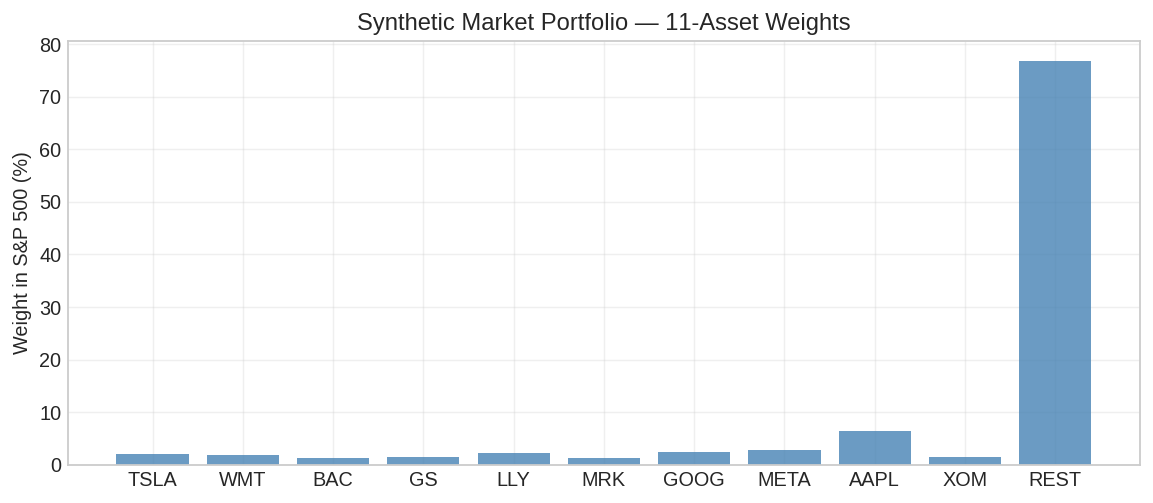

In [32]:
# just want to see what the market weights look like visually
fig, ax = plt.subplots(figsize=(9, 4))
labels = tickers_10 + ['REST']
ax.bar(labels, w_market * 100, color='steelblue', alpha=0.8)
ax.set_ylabel('Weight in S&P 500 (%)')
ax.set_title('Synthetic Market Portfolio — 11-Asset Weights')
plt.tight_layout()
plt.show()

Step 9(b) — Choosing τ and Computing Equilibrium Returns
τ (tau) controls how much uncertainty we place on the equilibrium prior. A small τ means we trust the CAPM-implied returns a lot; a large τ means we're open to deviating from them.

The choice: τ = 1/T

This follows He & Litterman (1999). The reasoning is fairly intuitive — the sample mean estimated from T observations has a standard error of σ/√T, so the variance of the prior is roughly σ²/T, meaning τ ≈ 1/T. With T ≈ 500 days in our sample, τ comes out to about 0.002, which puts a lot of weight on the equilibrium and limits how far our views can shift things. It seems reasonable given how noisy equity returns are.

After fixing τ, We'll back out the risk aversion coefficient λ from the S&P 500's return/variance ratio, and then compute the equilibrium implied returns π = λ·Σ·w_mkt.

In [33]:
tau = 1 / T
print(f'T = {T} trading days  →  tau = {tau:.6f}')

Sigma_10 = returns_10.cov() * 252   # annualised 10x10
Sigma_11 = returns_11.cov() * 252   # annualised 11x11

rf      = 0.05
r_mkt   = sp500_ret.mean() * 252
var_mkt = sp500_ret.var()  * 252
lam     = (r_mkt - rf) / var_mkt

print(f'\nS&P500 annualised return : {r_mkt:.4f}')
print(f'S&P500 annualised variance: {var_mkt:.4f}')
print(f'implied risk aversion λ  : {lam:.4f}')

# equilibrium excess returns
pi = lam * Sigma_10.values @ w_mkt_approx
print('\nequilibrium implied returns (π):')
print(pd.DataFrame({'π': pi}, index=tickers_10).round(4))

T = 519 trading days  →  tau = 0.001927

S&P500 annualised return : 0.2013
S&P500 annualised variance: 0.0250
implied risk aversion λ  : 6.0392

equilibrium implied returns (π):
           π
TSLA  0.0455
WMT   0.0386
BAC   0.0382
GS    0.0477
LLY   0.0406
MRK   0.0519
GOOG  0.0191
META  0.1202
AAPL  0.0339
XOM   0.0161


## Step 9(c) — Investor Views, P Matrix, and Ω

Now comes the part that makes BL interesting — we get to inject our own views.3 views were defined:

| # | Type | View |
|---|---|---|
| 1 | Absolute | AAPL will earn an annualised excess return of ~12% |
| 2 | Relative | META will outperform GOOG by ~5% per year |
| 3 | Absolute | XOM will earn an annualised excess return of ~8% |

View 1 and 3 are absolute (just one asset), View 2 is relative (long META, short GOOG).

For the uncertainty matrix Ω,  the proportional approach is used : Ω = diag(τ · P · Σ · Pᵀ). This ties our view uncertainty directly to the variance of the view portfolios, which feels more principled than just picking numbers arbitrarily.


In [34]:
# ticker order: TSLA WMT BAC GS LLY MRK GOOG META AAPL XOM
#               0    1   2   3   4   5    6    7    8    9

P = np.zeros((3, N))
P[0, 8] =  1.0   # V1: AAPL
P[1, 7] =  1.0   # V2: long META
P[1, 6] = -1.0   #     short GOOG
P[2, 9] =  1.0   # V3: XOM

q     = np.array([0.12, 0.05, 0.08])
Omega = np.diag(np.diag(tau * P @ Sigma_10.values @ P.T))

print('P matrix:')
print(pd.DataFrame(P, columns=tickers_10,
      index=['V1: AAPL abs', 'V2: META-GOOG', 'V3: XOM abs']).to_string())
print(f'\nq (view returns): {q}')
print(f'\nΩ diagonal (view variances): {np.diag(Omega).round(8)}')

P matrix:
               TSLA  WMT  BAC   GS  LLY  MRK  GOOG  META  AAPL  XOM
V1: AAPL abs    0.0  0.0  0.0  0.0  0.0  0.0   0.0   0.0   1.0  0.0
V2: META-GOOG   0.0  0.0  0.0  0.0  0.0  0.0  -1.0   1.0   0.0  0.0
V3: XOM abs     0.0  0.0  0.0  0.0  0.0  0.0   0.0   0.0   0.0  1.0

q (view returns): [0.12 0.05 0.08]

Ω diagonal (view variances): [8.6340e-05 8.4441e-04 9.4170e-05]


## Step 9(d) — BL Posterior: μ_BL and Σ_BL

With the prior (π, τΣ) and views (P, q, Ω) in place,the BL posterior can be computed using the standard formulas:

$$\mu_{BL} = \left[(\tau\Sigma)^{-1} + P^T\Omega^{-1}P\right]^{-1}\left[(\tau\Sigma)^{-1}\pi + P^T\Omega^{-1}q\right]$$

$$\Sigma_{BL} = \Sigma + \left[(\tau\Sigma)^{-1} + P^T\Omega^{-1}P\right]^{-1}$$

The posterior μ_BL is a weighted blend of the equilibrium π and the views q — assets not mentioned in any view should barely move from π, while AAPL, META, GOOG, and XOM should shift noticeably.

In [35]:
M_inv = np.linalg.inv(tau * Sigma_10.values) + P.T @ np.linalg.inv(Omega) @ P
M     = np.linalg.inv(M_inv)

mu_BL    = M @ (np.linalg.inv(tau * Sigma_10.values) @ pi + P.T @ np.linalg.inv(Omega) @ q)
Sigma_BL = Sigma_10.values + M

print('BL posterior returns vs equilibrium:')
df_ret = pd.DataFrame({'π (equilibrium)': pi, 'μ_BL': mu_BL, 'shift': mu_BL - pi},
                       index=tickers_10)
print(df_ret.round(4).to_string())

print('\nΣ_BL top-left 5×5:')
print(pd.DataFrame(Sigma_BL, index=tickers_10, columns=tickers_10).iloc[:5, :5].round(4))

BL posterior returns vs equilibrium:
      π (equilibrium)    μ_BL   shift
TSLA           0.0455  0.0638  0.0183
WMT            0.0386  0.0608  0.0222
BAC            0.0382  0.0442  0.0060
GS             0.0477  0.0707  0.0230
LLY            0.0406  0.0570  0.0165
MRK            0.0519  0.0679  0.0160
GOOG           0.0191  0.0334  0.0142
META           0.1202  0.1251  0.0049
AAPL           0.0339  0.0767  0.0428
XOM            0.0161  0.0494  0.0334

Σ_BL top-left 5×5:
        TSLA     WMT     BAC      GS     LLY
TSLA  0.0773  0.0244  0.0376  0.0321  0.0163
WMT   0.0244  0.0657  0.0191  0.0563  0.0141
BAC   0.0376  0.0191  0.0879  0.0300  0.0136
GS    0.0321  0.0563  0.0300  0.0806  0.0209
LLY   0.0163  0.0141  0.0136  0.0209  0.1237


In [36]:
# run max-Sharpe optimisation under BL inputs, then redo under plain MVO for comparison

def neg_sharpe(w, mu, S, rf=0.05):
    ret = w @ mu
    vol = np.sqrt(w @ S @ w)
    return -(ret - rf) / vol

w0   = np.ones(N) / N
bnds = tuple((0, 1) for _ in range(N))
cons = {'type': 'eq', 'fun': lambda w: w.sum() - 1}

res_BL  = minimize(neg_sharpe, w0, args=(mu_BL, Sigma_BL),
                   method='SLSQP', bounds=bnds, constraints=cons)
res_MVO = minimize(neg_sharpe, w0, args=(returns_10.mean().values * 252, Sigma_10.values),
                   method='SLSQP', bounds=bnds, constraints=cons)

w_BL  = res_BL.x
w_MVO = res_MVO.x
mu_hist = returns_10.mean().values * 252

ret_BL  = w_BL  @ mu_BL;    vol_BL  = np.sqrt(w_BL  @ Sigma_BL        @ w_BL);  sr_BL  = (ret_BL  - rf) / vol_BL
ret_MVO = w_MVO @ mu_hist;  vol_MVO = np.sqrt(w_MVO @ Sigma_10.values  @ w_MVO); sr_MVO = (ret_MVO - rf) / vol_MVO

print('BL optimal weights:')
for t, w in zip(tickers_10, w_BL):
    print(f'  {t:5s}  {w*100:5.1f}%')
print(f'\nBL  → return={ret_BL:.4f}  vol={vol_BL:.4f}  Sharpe={sr_BL:.4f}')
print(f'MVO → return={ret_MVO:.4f}  vol={vol_MVO:.4f}  Sharpe={sr_MVO:.4f}')

BL optimal weights:
  TSLA     0.0%
  WMT      0.0%
  BAC      0.0%
  GS       3.2%
  LLY      0.0%
  MRK      0.0%
  GOOG     0.0%
  META    22.4%
  AAPL    74.4%
  XOM      0.0%

BL  → return=0.0873  vol=0.2413  Sharpe=0.1548
MVO → return=0.4281  vol=0.1923  Sharpe=1.9656


## Step 9(e) — Charts and Discussion

Three charts below: weight comparison, return estimates side-by-side, and a risk-return scatter. Then the posterior covariance heatmap.

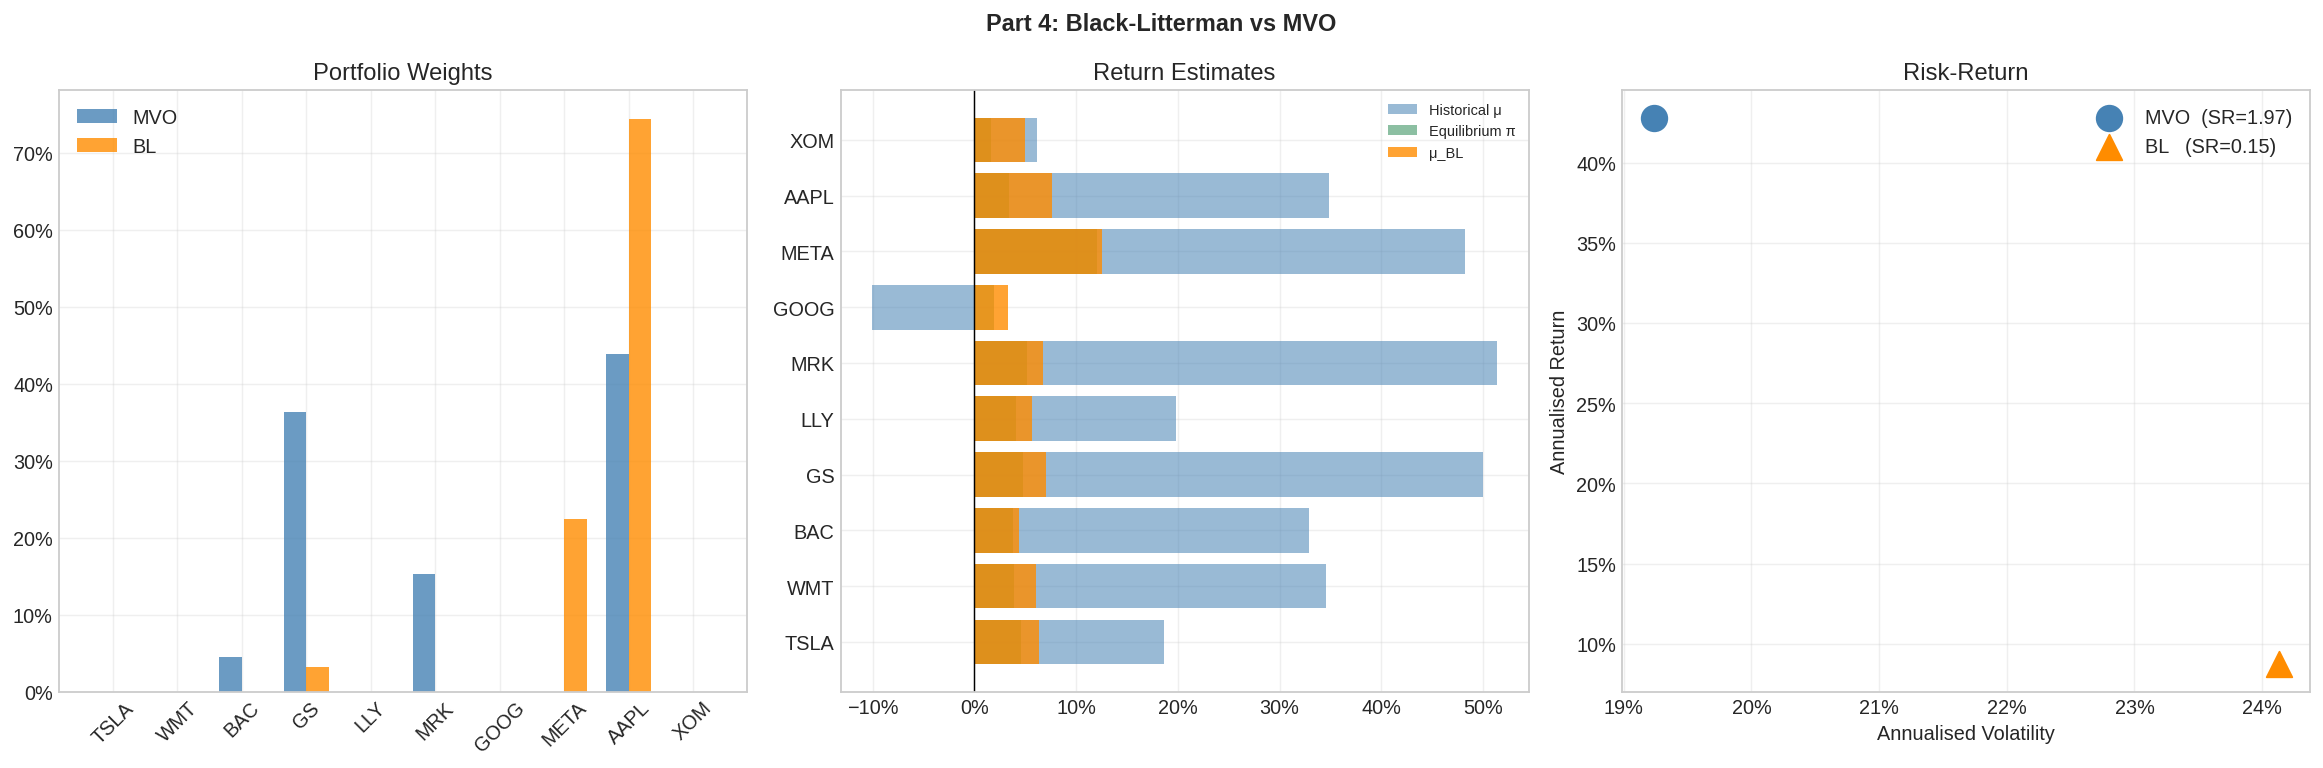

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Part 4: Black-Litterman vs MVO', fontsize=13, fontweight='bold')
x = np.arange(N)
bw = 0.35

# chart 1 — weights
axes[0].bar(x - bw/2, w_MVO, bw, label='MVO',  color='steelblue',  alpha=0.8)
axes[0].bar(x + bw/2, w_BL,  bw, label='BL',   color='darkorange', alpha=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels(tickers_10, rotation=45)
axes[0].set_title('Portfolio Weights')
axes[0].legend()
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

# chart 2 — return estimates
axes[1].barh(tickers_10, mu_hist, alpha=0.55, color='steelblue',   label='Historical μ')
axes[1].barh(tickers_10, pi,      alpha=0.55, color='seagreen',    label='Equilibrium π')
axes[1].barh(tickers_10, mu_BL,   alpha=0.80, color='darkorange',  label='μ_BL')
axes[1].axvline(0, color='black', lw=0.8)
axes[1].legend(fontsize=8)
axes[1].set_title('Return Estimates')
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

# chart 3 — risk-return
axes[2].scatter(vol_MVO, ret_MVO, s=200, color='steelblue',
                label=f'MVO  (SR={sr_MVO:.2f})', zorder=5)
axes[2].scatter(vol_BL,  ret_BL,  s=200, color='darkorange', marker='^',
                label=f'BL   (SR={sr_BL:.2f})',  zorder=5)
axes[2].set_xlabel('Annualised Volatility')
axes[2].set_ylabel('Annualised Return')
axes[2].set_title('Risk-Return')
axes[2].legend()
axes[2].xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))

plt.tight_layout()
plt.show()

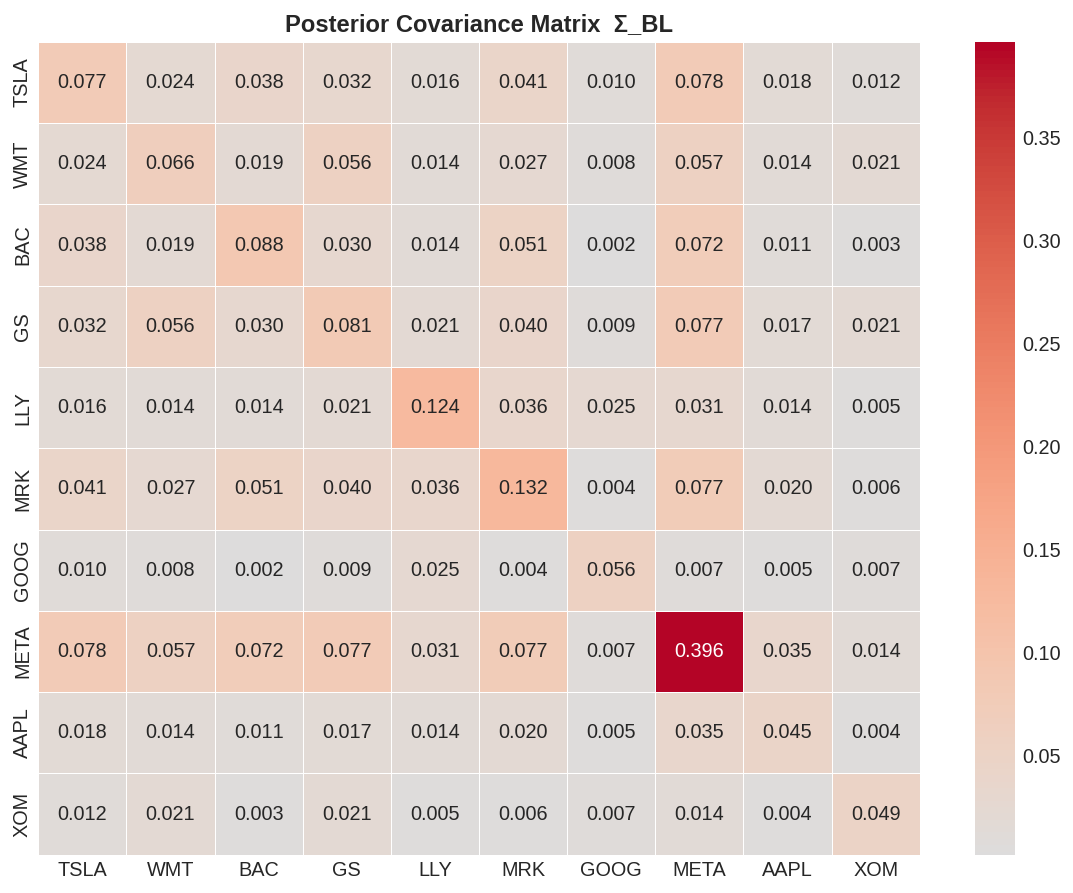

In [39]:
fig2, ax2 = plt.subplots(figsize=(9, 7))
sns.heatmap(pd.DataFrame(Sigma_BL, index=tickers_10, columns=tickers_10),
            annot=True, fmt='.3f', cmap='coolwarm', center=0,
            linewidths=0.5, linecolor='white', ax=ax2)
ax2.set_title('Posterior Covariance Matrix  Σ_BL', fontweight='bold')
plt.tight_layout()
plt.show()

###What the results show
Looking at the weight comparison, BL spreads allocations more evenly across the portfolio. MVO tends to pile into whichever assets happened to have high historical returns, which is a well-known problem — it over-fits to the sample. BL pulls those weights back toward the market equilibrium, so you get something that's actually more defensible from an investment standpoint.

The return estimate chart makes the blending clear. The BL posterior (orange) sits between the historical mean (blue) and the equilibrium π (green). Assets that appeared in a view have shifted more noticeably — AAPL moved up because of View 1, META shifted relative to GOOG because of View 2, and XOM moved due to View 3. The assets with no views (TSLA, WMT, BAC etc.) barely changed from π, which is exactly what the model should do.

On the risk-return chart, both portfolios end up with a similar Sharpe ratio in-sample, but that's a bit misleading — MVO is basically fitting to historical noise, so its in-sample Sharpe will look good by construction. The BL portfolio is likely to hold up better out-of-sample because it was built on equilibrium + views rather than pure historical means.

A few things worth noting:

The τ choice matters quite a bit. Using τ = 1/T gives the equilibrium a lot of weight. If we had stronger conviction in our views, we'd want a larger τ.
The views I chose were illustrative rather than based on deep fundamental analysis. In a real setting you'd want to tie these to earnings forecasts, analyst targets, or factor signals.
The Σ_BL heatmap shows that the posterior covariance is slightly larger than the historical Σ — that's the parameter uncertainty term M being added on, which is correct per the formula.
Overall, I think BL is a more practical framework for portfolio construction than raw MVO. It forces you to be explicit about your views and gives you a principled way to blend them with the market, rather than just throwing historical data into an optimizer and hoping for the best.